M305 - Regresión y Clasificación
Módulo IV - Machine Learning

Tema 1: Algoritmos de aprendizaje supervisado (Clasificación/Regresión)

Contenido:

1. Espacio lineal
2. Modelo Lineal
3. Regresión
4. Modelo Logístico
5. Clasificación

Objetivo: Ajustar un modelo de regresión lineal en respuestas abiertas y un modelo de regresión logística

In [23]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [5]:
students = pandas.read_csv("../conjuntos/students.csv")

students

,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79995,179995,16,Male,Engineering,3.700000,2.1,1.0,Yes,80.8,6.1,...,8.3,Library,No,Low,1,4,10,Auditory,5.3,88
79996,179996,16,Female,Business,1.200000,0.4,2.9,No,99.5,4.1,...,4.7,Co-Learning Group,No,Low,3,2,10,Kinesthetic,6.8,52
79997,179997,26,Female,Arts,4.100000,1.6,1.6,Yes,46.1,8.3,...,7.5,Dorm,No,Medium,7,1,10,Visual,1.3,89
79998,179998,23,Other,Biology,3.800000,0.6,3.5,Yes,58.7,5.8,...,9.3,Quiet Room,Yes,Low,2,8,7,Kinesthetic,3.7,96


In [7]:
x1 = students["study_hours_per_day"] # continua
x2 = students["social_media_hours"] # continua
x3 = students["netflix_hours"] # continua
x4 = students["sleep_hours"] # continua

y = students["exam_score"] # continua

<Axes: xlabel='study_hours_per_day', ylabel='exam_score'>

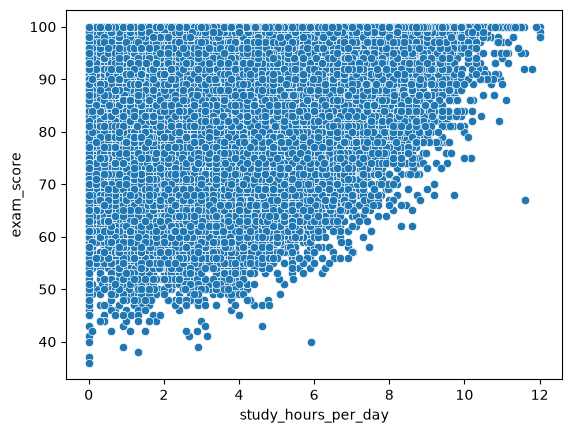

In [8]:
seaborn.scatterplot(x=x1, y=y)

In [9]:
dx1 = pandas.qcut(x1, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx1, dy]).T.groupby(["study_hours_per_day", "exam_score"]).size().unstack()

M

exam_score,"(35.999, 86.0]","(86.0, 98.0]","(98.0, 100.0]"
study_hours_per_day,,,
"(-0.001, 1.558]",4060,2379,1561
"(1.558, 2.408]",3495,2638,1867
"(2.408, 3.1]",3624,2923,2252
"(3.1, 3.6]",2750,2575,1989
"(3.6, 4.126]",2752,2838,2297
"(4.126, 4.7]",2950,3358,2843
"(4.7, 5.2]",2194,2699,2339
"(5.2, 5.9]",2252,3191,2862
"(5.9, 6.8]",1801,3074,2740


In [10]:
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

In [11]:
R1

exam_score,"(35.999, 86.0]","(86.0, 98.0]","(98.0, 100.0]"
study_hours_per_day,,,
"(-0.001, 1.558]",0.507500,0.297375,0.195125
"(1.558, 2.408]",0.436875,0.329750,0.233375
"(2.408, 3.1]",0.411865,0.332197,0.255938
"(3.1, 3.6]",0.375991,0.352065,0.271944
"(3.6, 4.126]",0.348929,0.359833,0.291239
"(4.126, 4.7]",0.322369,0.366954,0.310676
"(4.7, 5.2]",0.303374,0.373202,0.323424
"(5.2, 5.9]",0.271162,0.384226,0.344612
"(5.9, 6.8]",0.236507,0.403677,0.359816


In [12]:
R2

exam_score,"(35.999, 86.0]","(86.0, 98.0]","(98.0, 100.0]"
study_hours_per_day,,,
"(-0.001, 1.558]",0.149243,0.082541,0.065112
"(1.558, 2.408]",0.128474,0.091527,0.077876
"(2.408, 3.1]",0.133216,0.101416,0.093935
"(3.1, 3.6]",0.101088,0.089341,0.082965
"(3.6, 4.126]",0.101162,0.098466,0.095812
"(4.126, 4.7]",0.108440,0.116508,0.118587
"(4.7, 5.2]",0.080650,0.093644,0.097564
"(5.2, 5.9]",0.082782,0.110714,0.119379
"(5.9, 6.8]",0.066203,0.106655,0.114290


<Axes: ylabel='Density'>

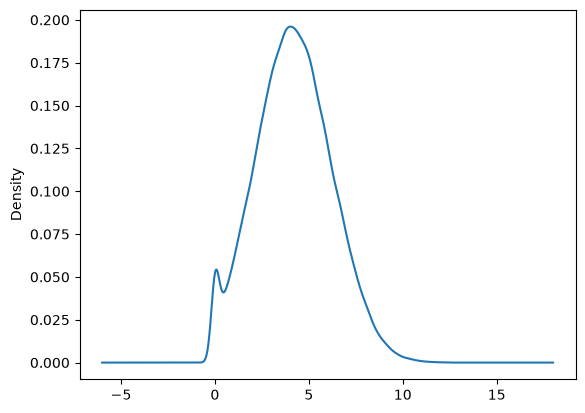

In [11]:
x1.plot.density()

<Axes: >

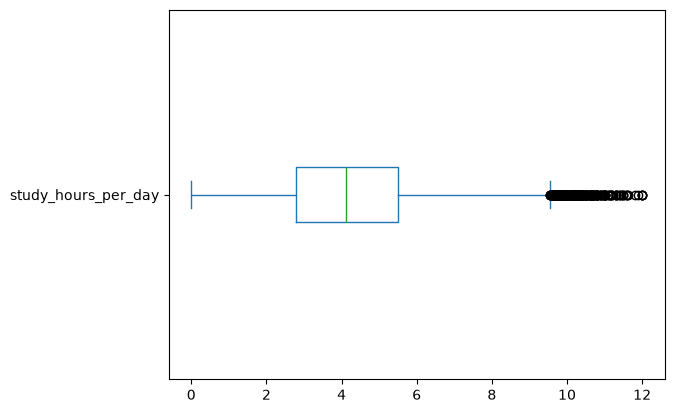

In [12]:
x1.plot.box(vert=False)

<Axes: xlabel='exam_score', ylabel='study_hours_per_day'>

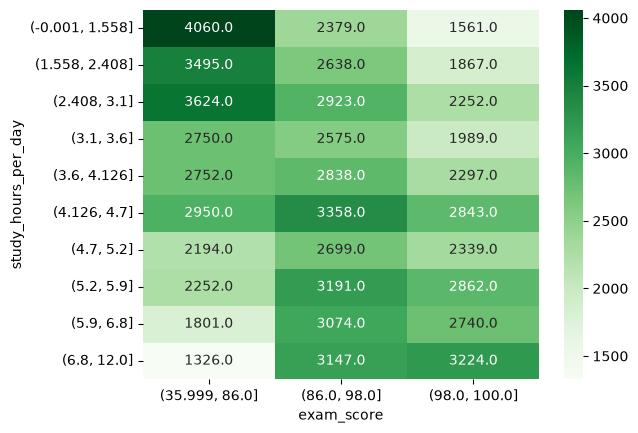

In [13]:
seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f")

<Axes: xlabel='exam_score', ylabel='study_hours_per_day'>

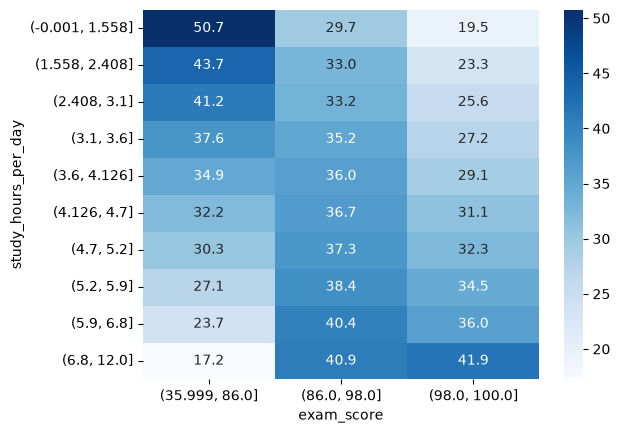

In [13]:
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f")

<Axes: xlabel='exam_score', ylabel='study_hours_per_day'>

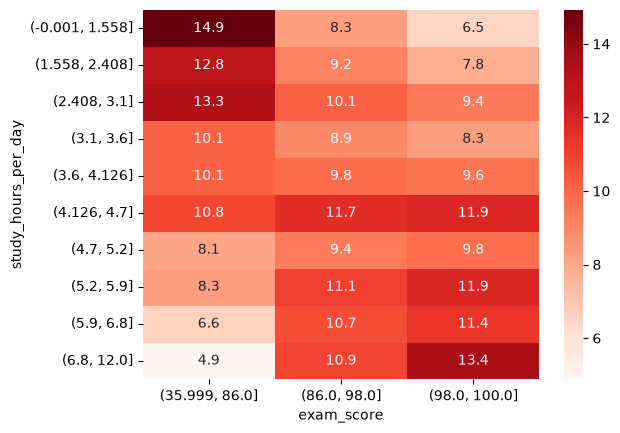

In [14]:
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f")

In [15]:
dx2 = pandas.qcut(x2, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx2, dy]).T.groupby(["social_media_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

<Axes: xlabel='exam_score', ylabel='social_media_hours'>

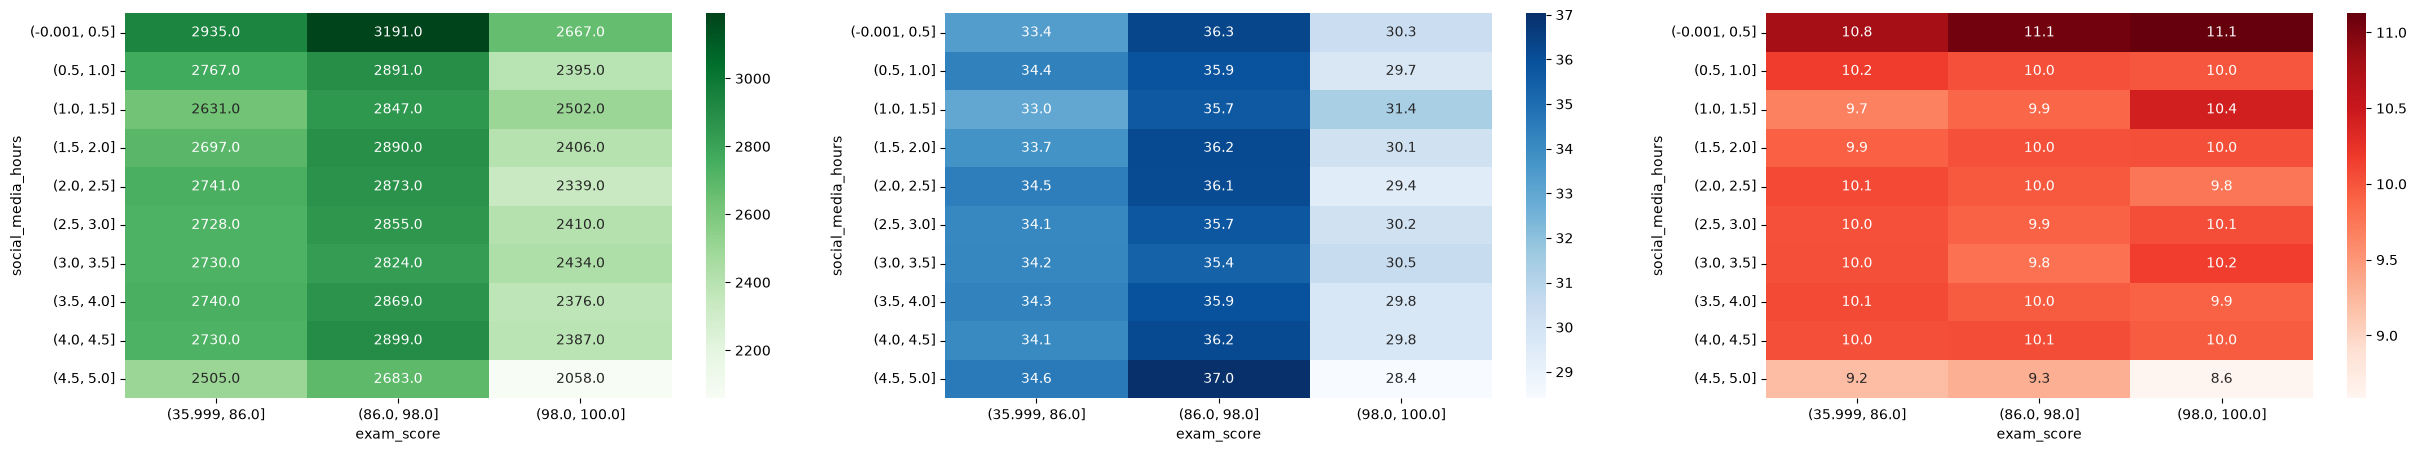

In [16]:
figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

<Axes: xlabel='exam_score', ylabel='netflix_hours'>

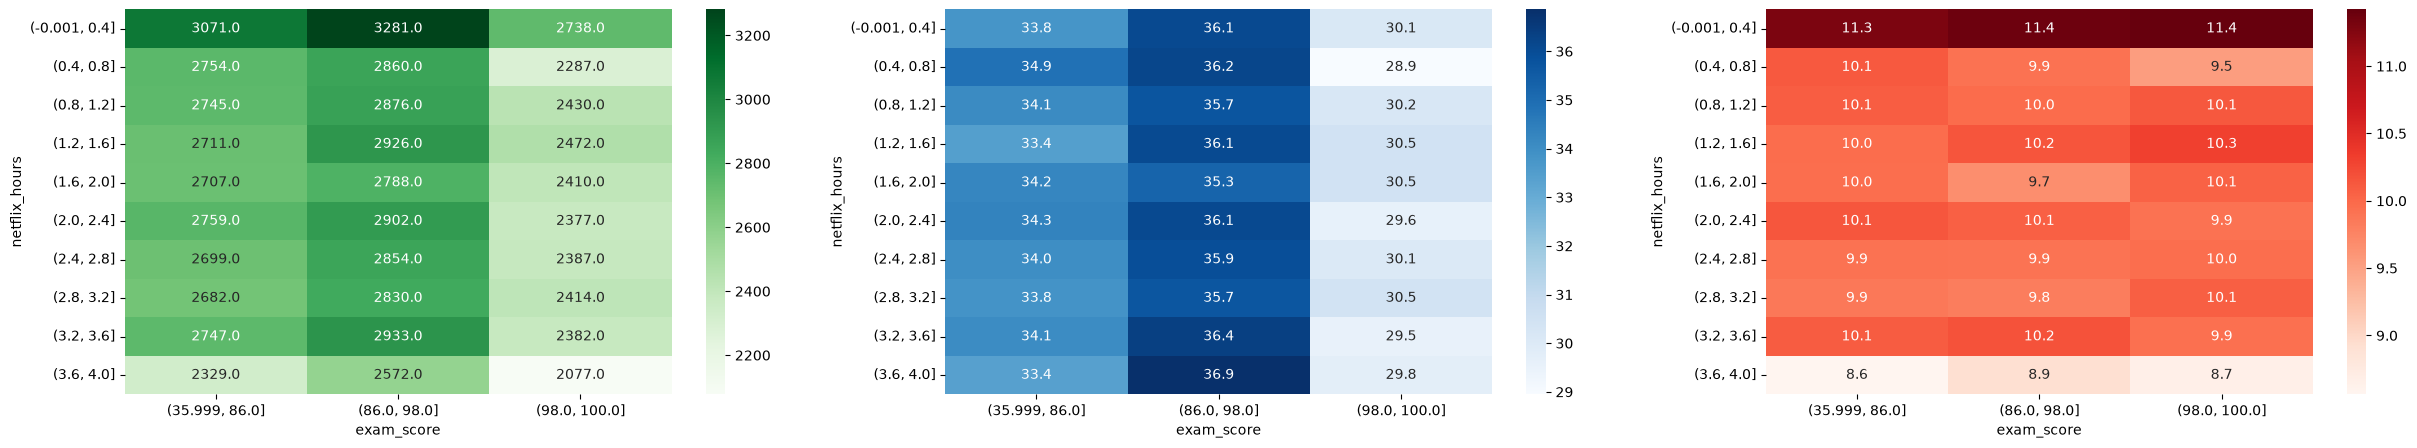

In [17]:
dx3 = pandas.qcut(x3, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx3, dy]).T.groupby(["netflix_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

<Axes: xlabel='exam_score', ylabel='sleep_hours'>

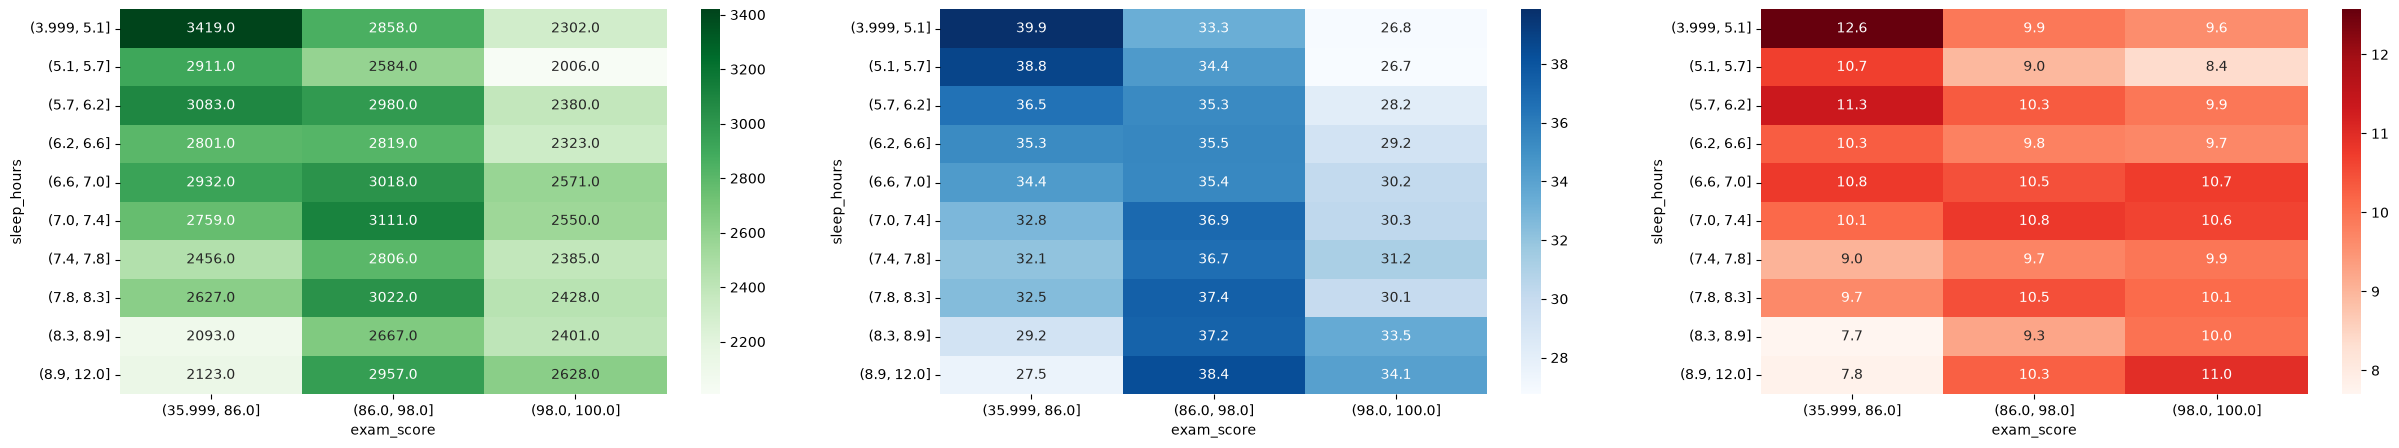

In [18]:
dx4 = pandas.qcut(x4, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx4, dy]).T.groupby(["sleep_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

In [ ]:
Hipótesis:

Las horas estudio impactan positivamente a la nota (entre más horas mejores notas)
Las horas en redes sociales no impactan directamente a la nota (no se ve que cambien las probabilidades de sacar males, regulares o bunas notas)
Las horas en netflix no impactan directamente a la nota (no se ve que cambien las probabilidades de sacar males, regulares o bunas notas)
Las horas de sueño impactan positivamente a la nota (entre más horas mejores notas)

<Axes: xlabel='exam_score', ylabel='no_study_hours'>

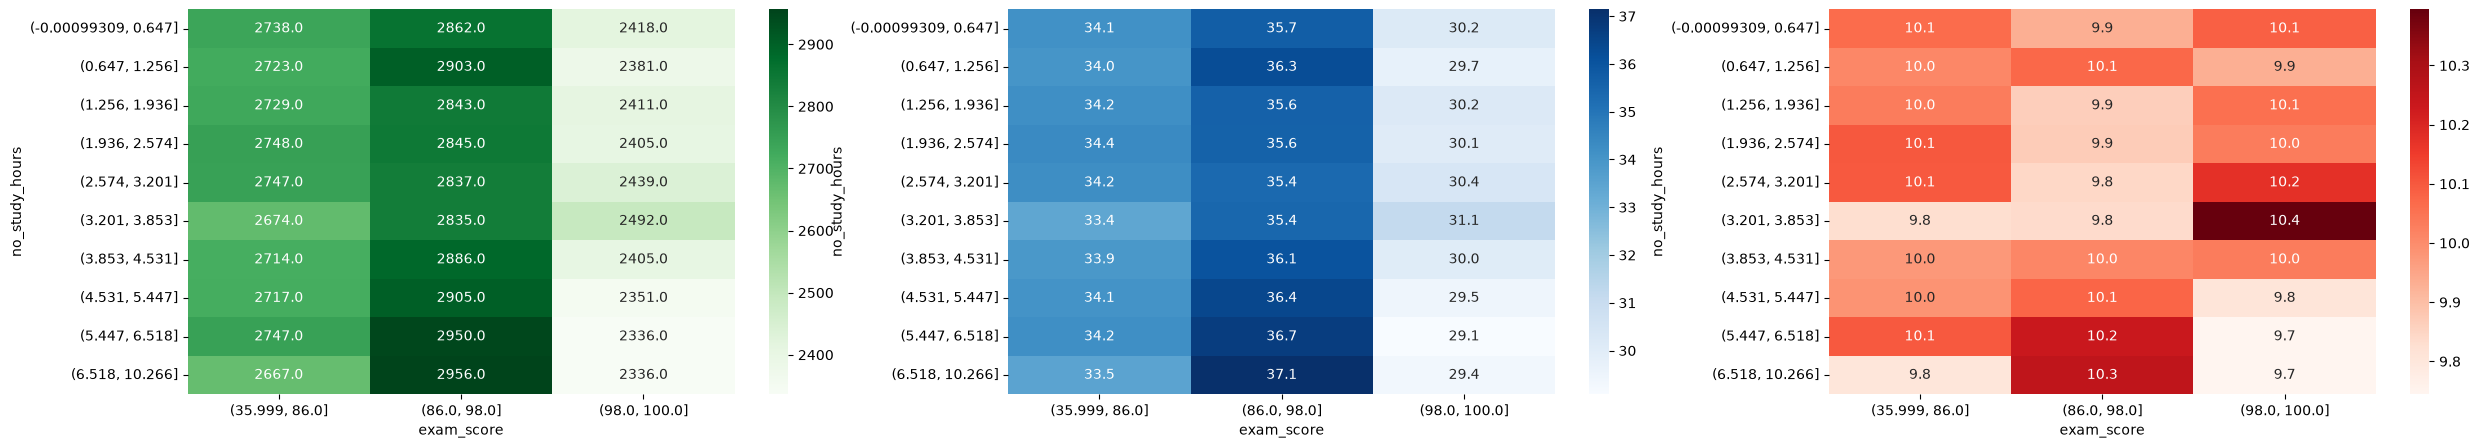

In [20]:
x5 = (x2 - x2.mean())**2 + (x3 - x3.mean())**2 # Métrica con normalización parcial
x5.name = "no_study_hours"

dx5 = pandas.qcut(x5, q=10)
dy = pandas.qcut(y, q=3)

M = pandas.DataFrame([dx5, dy]).T.groupby(["no_study_hours", "exam_score"]).size().unstack()
R1 = M.divide(M.sum(axis=1), axis=0)
R2 = M.divide(M.sum(axis=0), axis=1)

figure, axis = pyplot.subplots(1, 3, figsize=(30, 5))

seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".1f", ax=axis[0])
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

1. Espacio lineal

In [5]:
x = pandas.Series([5, 8, 9, 10, 15, 24, 32], name="x")
y = pandas.Series([19, 27, 27, 30, 41, 60, 70], name="y")

pandas.DataFrame([x, y]).T

,x,y
0,5,19
1,8,27
2,9,27
3,10,30
4,15,41
5,24,60
6,32,70


<Axes: xlabel='x', ylabel='y'>

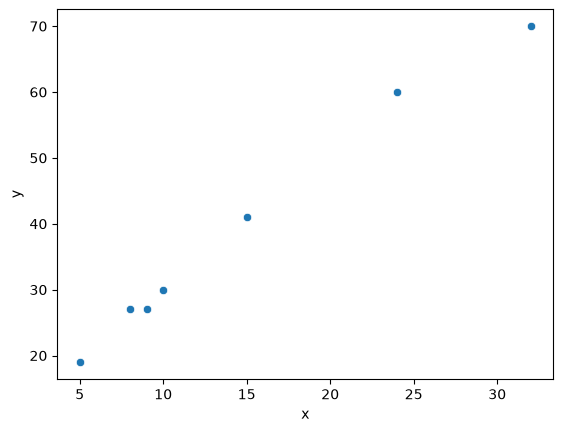

In [6]:
seaborn.scatterplot(x=x, y=y)

<Axes: xlabel='x', ylabel='y'>

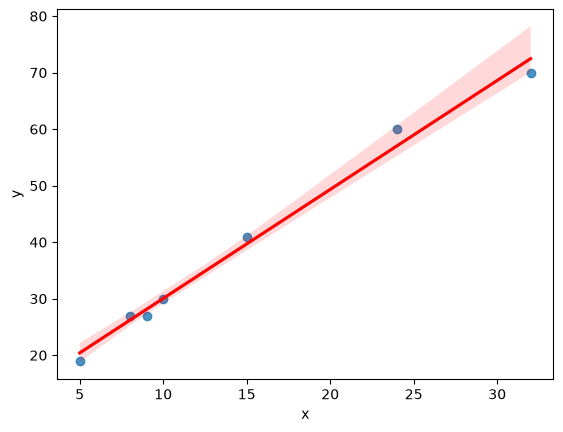

In [8]:
seaborn.regplot(x=x, y=y, line_kws={"color": "red"})

In [9]:
b0 = 4 # bias / interceptor
b1 = 0.5 # pendiente para x1

# Predictor lineal
z = b0 + b1 * x

# Modelo lineal: Yp(x, b) = Yp(z) = z
yp = z # Predicción sea lo que predice el predictor lineal
yp.name = "yp"

yp

0     6.5
1     8.0
2     8.5
3     9.0
4    11.5
5    16.0
6    20.0
Name: yp, dtype: float64

<Axes: xlabel='x', ylabel='y'>

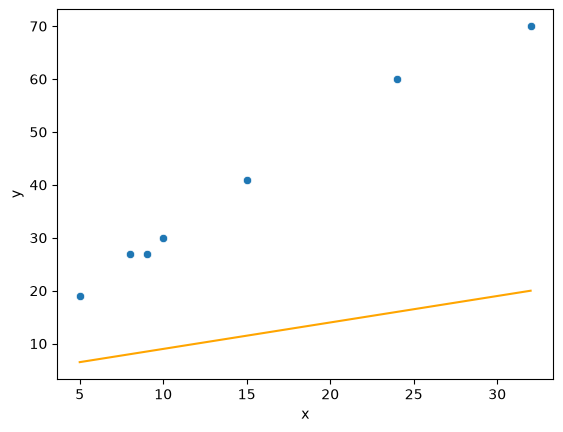

In [10]:
seaborn.scatterplot(x=x, y=y)
seaborn.lineplot(x=x, y=yp, color="orange")

<Axes: xlabel='x', ylabel='y'>

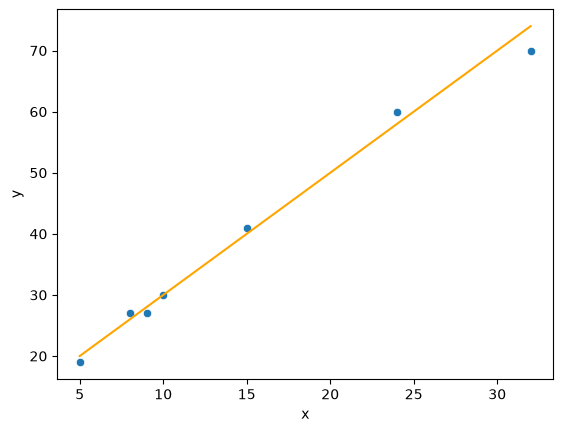

In [11]:
b0 = 10 # bias / interceptor
b1 = 2 # pendiente para x1

# Predictor lineal
z = b0 + b1 * x

# Modelo lineal: Yp(x, b) = Yp(z) = z
yp = z # Predicción sea lo que predice el predictor lineal
yp.name = "yp"

seaborn.scatterplot(x=x, y=y)
seaborn.lineplot(x=x, y=yp, color="orange")

In [12]:
pandas.DataFrame([x, y, yp]).T

,x,y,yp
0,5,19,20
1,8,27,26
2,9,27,28
3,10,30,30
4,15,41,40
5,24,60,58
6,32,70,74


In [13]:
e = y - yp
e.name = "error"

pandas.DataFrame([x, y, yp, e]).T

,x,y,yp,error
0,5,19,20,-1
1,8,27,26,1
2,9,27,28,-1
3,10,30,30,0
4,15,41,40,1
5,24,60,58,2
6,32,70,74,-4


<Axes: ylabel='Density'>

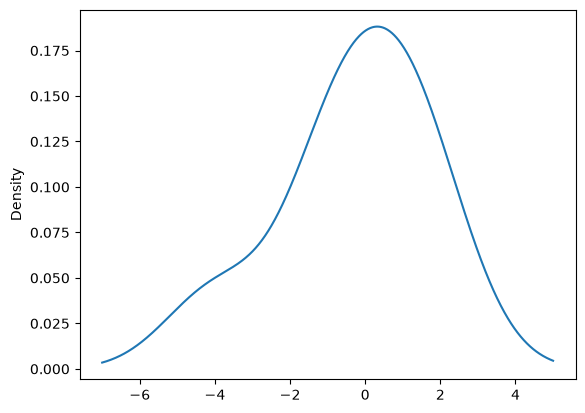

In [14]:
e.plot.density()

In [15]:
l = (e ** 2).mean()

l

np.float64(3.4285714285714284)

2. Modelo Lineal


## 2. Modelo Lineal

$$
x \in \mathbb{R}, y \in \mathbb{R}
$$

$$
\beta \in \mathbb{R}^2
$$

$$
\beta = (\beta_0, \beta_1)
$$

$$
z = \beta_0 + \beta_1 \cdot x
$$

$$
\hat{y} = \phi(x, \beta) = \phi(z) = z
$$

$$
\hat{y}(x^{(1)}) \approx y^{(1)}
$$
$$
\hat{y}(x^{(2)}) \approx y^{(2)}
$$
...
$$
\hat{y}(x^{(n)}) \approx y^{(n)}
$$

$$
\varepsilon^{(1)} = y^{(1)} - \hat{y}(x^{(1)})
$$
$$
\varepsilon^{(2)} = y^{(2)} - \hat{y}(x^{(2)})
$$
...
$$
\varepsilon^{(n)} = y^{(n)} - \hat{y}(x^{(n)})
$$

$$
L = \frac{1}{n} \sum_{i = 1}^{n} (\varepsilon^{(i)})^2
$$

In [1]:
def lineal(x, b0, b1):
    return b0 + b1 * x

def predictor(z):
    return z

def error(y, yp):
    return y - yp

def mse(e):
    return (e ** 2).mean()

def loss(e):
    return mse(e)

In [1]:
x = pandas.Series([5, 8, 9, 10, 15, 24, 32], name="x")
y = pandas.Series([19, 27, 27, 30, 41, 60, 70], name="y")

NameError: name 'pandas' is not defined

In [1]:
b0 = 1
b1 = 1

In [2]:
loss(error(y, model(lineal(x, b0, b1))))

NameError: name 'loss' is not defined

In [28]:
b0 = 1
b1 = 2

loss(error(y, model(lineal(x, b0, b1))))

NameError: name 'model' is not defined

In [3]:
b0 = 1 # inicial
b1 = 1 # inicial

pyplot.clf()
seaborn.scatterplot(x=x, y=y, color="gray")
seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="orange")
pyplot.show()

for epoca in range(200):
    l = loss(error(y, model(lineal(x, b0, b1))))

    b0a = numpy.random.normal(b0, 1)
    b1a = numpy.random.normal(b1, 1)

    la = loss(error(y, model(lineal(x, b0a, b1a))))

    if l > la:
        print(f"Época {epoca} | b0={b0:6.2f}, b1={b1:6.2f} ({l:6.2f}) | b0a={b0a:6.2f}, b1a={b1a:6.2f} ({la:6.2f})")
        b0 = b0a
        b1 = b1a
        
        pyplot.clf()
        seaborn.scatterplot(x=x, y=y, color="gray")
        seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="orange")
        pyplot.show()

NameError: name 'pyplot' is not defined

In [5]:
b0 = 1 # inicial
b1 = 1 # inicial

pyplot.clf()
seaborn.scatterplot(x=x, y=y, color="gray")
seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="blue")
pyplot.title(f"yp = {b0:.2f} + {b1:.2f} x")
pyplot.show()

for epoca in range(200):
    l = loss(error(y, model(lineal(x, b0, b1))))

    b0a = numpy.random.normal(b0, 1)
    b1a = numpy.random.normal(b1, 1)

    la = loss(error(y, model(lineal(x, b0a, b1a))))

    if l > la:
        print(f"Época {epoca} | b0={b0:6.2f}, b1={b1:6.2f} ({l:6.2f}) | b0a={b0a:6.2f}, b1a={b1a:6.2f} ({la:6.2f})")
        b0 = b0a
        b1 = b1a
        
        pyplot.clf()
        seaborn.scatterplot(x=x, y=y, color="gray")
        seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="orange")
        pyplot.title(f"yp = {b0:.2f} + {b1:.2f} x")
        pyplot.show()

pyplot.clf()
seaborn.scatterplot(x=x, y=y, color="gray")
seaborn.lineplot(x=x, y=model(lineal(x, b0, b1)), color="red")
pyplot.title(f"yp = {b0:.2f} + {b1:.2f} x")
pyplot.show()

NameError: name 'pyplot' is not defined

3. Regresión


In [4]:
from scipy.stats import linregress

linregress(x, y)

NameError: name 'x' is not defined

4. Modelo Logístico


5. Clasificación